# ORL Faces: PCA, SVM and Ensemble Methods

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Study classification of face images with reduced-dimensional features.

**Approach:** PCA, support vector machines and ensemble models.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Projet 2 : Ensamble Learning 2 </span>
    </span>
    </center>
<br>


### GUERBOUZ MOHAMMED ALAA EDDINE

### Step 1: Import Necessary Libraries
We start by importing the necessary libraries for data manipulation, visualization, and machine learning. These libraries include:
- `numpy` for numerical operations.
- `os` for file handling.
- `PIL` for image processing.
- `sklearn` modules for machine learning tasks such as data splitting, dimensionality reduction, and classification..

In [4]:
# Import necessary libraries
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler
from PIL import Image

### Step 2: Load and Preprocess the Dataset
We load the images from the `att_faces` directory and preprocess them. Each image is:
- Converted to grayscale using `img.convert('L')`.
- Resized to a consistent dimension (e.g., 64x64 pixels) using `img.resize()`.
- Flattened into a 1D array for use in machine learning algorithms.

The dataset is stored in two arrays:
- `X`: Contains the flattened image data.
- `y`: Contains the corresponding labels (e.g., person IDs).lysis..

In [16]:
import os
import numpy as np
from PIL import Image

def load_images_from_folder(folder):
    images = []
    labels = []
    for subdir in os.listdir(folder):
        subdir_path = os.path.join(folder, subdir)
        if os.path.isdir(subdir_path):
            # Extract the numeric part of the subdirectory name
            label = int(subdir[1:])  # Remove the 's' and convert to integer
            for filename in os.listdir(subdir_path):
                img_path = os.path.join(subdir_path, filename)
                try:
                    with Image.open(img_path) as img:
                        img = img.convert('L')  # Convert to grayscale
                        img = img.resize((64, 64))  # Resize if necessary
                        images.append(np.array(img).flatten())
                        labels.append(label)
                except PermissionError:
                    print(f"Permission denied: {img_path}")
                except Exception as e:
                    print(f"Error processing {img_path}: {e}")
    return np.array(images), np.array(labels)

# Load images and labels
X, y = load_images_from_folder("./att_faces/orl_faces")

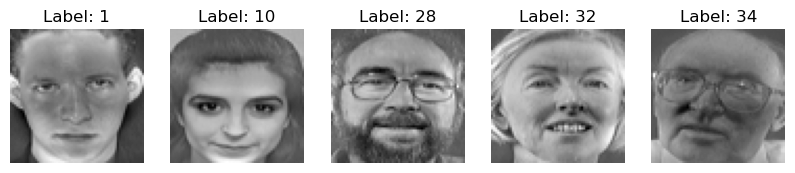

In [22]:
import matplotlib.pyplot as plt

def plot_sample_images(images, labels, num_samples=5):
    plt.figure(figsize=(10, 10))
    for i in range(num_samples):
        plt.subplot(1, num_samples, i+1)
        plt.imshow(images[i].reshape(64, 64), cmap='gray')
        plt.title(f"Label: {labels[i]}")
        plt.axis('off')
    plt.show()

plot_sample_images(X_train, y_train)

### Step 3: Split the Dataset into Training and Testing Sets
We split the dataset into training and testing sets using an 80-20 split:
- 80% of the data is used for training (`X_train`, `y_train`).
- 20% of the data is used for testing (`X_test`, `y_test`).

This ensures that we can evaluate the model's performance on unseen data.eady for modeling..

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Step 3: Split the Dataset into Training and Testing Sets
We split the dataset into training and testing sets using an 80-20 split:
- 80% of the data is used for training (`X_train`, `y_train`).
- 20% of the data is used for testing (`X_test`, `y_test`).

This ensures that we can evaluate the model's performance on unseen data.g survival..

In [18]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Step 5: Apply PCA for Dimensionality Reduction
We apply Principal Component Analysis (PCA) to reduce the dimensionality of the data:
- PCA transforms the high-dimensional image data into a lower-dimensional space.
- We retain the top 100 principal components, which capture most of the variance in the data.

This step helps in speeding up the training process and reducing overfitting.

In [19]:
pca = PCA(n_components=100)  # Adjust the number of components as needed
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

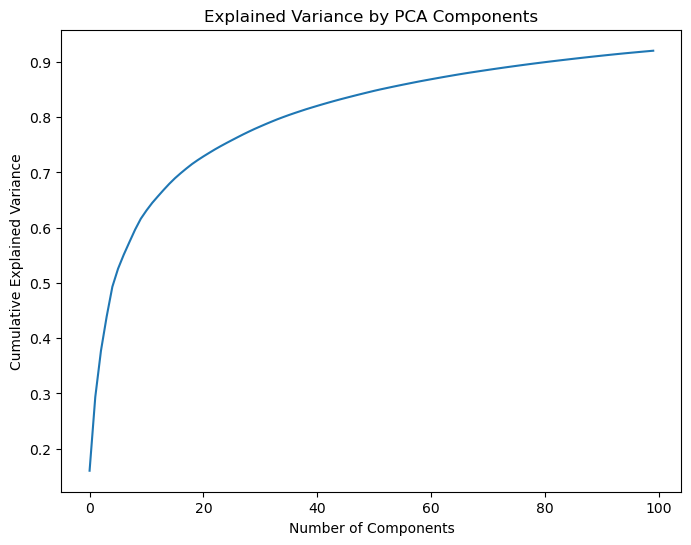

In [23]:
plt.figure(figsize=(8, 6))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance by PCA Components')
plt.show()

### Step 6: Train a Classifier
We use a Random Forest classifier to train the model on the training data:
- Random Forest is an ensemble learning method that combines multiple decision trees.
- It is robust to overfitting and works well for classification tasks.

The model is trained on the PCA-transformed training data (`X_train_pca`).

In [20]:
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train_pca, y_train)

RandomForestClassifier(random_state=42)

### Step 7: Evaluate the Model
We evaluate the model's performance on the test set using the following metrics:
- **Accuracy**: The proportion of correctly classified images.
- **Precision**: The proportion of true positives among all predicted positives.
- **Recall**: The proportion of true positives among all actual positives.
- **F1-score**: The harmonic mean of precision and recall.

These metrics are displayed in a classification report.

In [21]:
y_pred = clf.predict(X_test_pca)
print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

              precision    recall  f1-score   support

           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      1.00      1.00         3
           4       0.50      1.00      0.67         1
           5       0.50      1.00      0.67         1
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         2
           8       0.80      1.00      0.89         4
           9       1.00      1.00      1.00         4
          10       1.00      1.00      1.00         1
          11       1.00      0.50      0.67         2
          12       1.00      1.00      1.00         4
          13       1.00      1.00      1.00         3
          14       1.00      1.00      1.00         3
          16       1.00      0.67      0.80         6
          17       1.00      1.00      1.00         2
          18       1.00      1.00      1.00         2
          19       0.67    

### Step 8: Test with External Images
We test the trained model on external images (images not part of the original dataset):
- The external images are preprocessed in the same way as the training images.
- The model predicts the label for each external image.

This step helps in verifying the model's generalization capability.

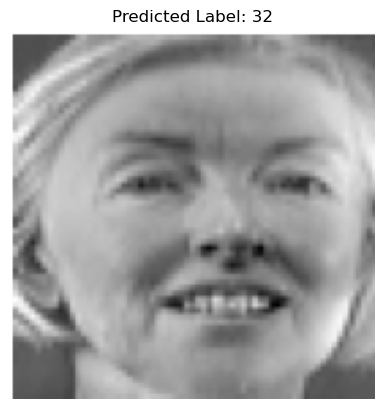

Predicted Label for test.PNG: 32
Actuall :


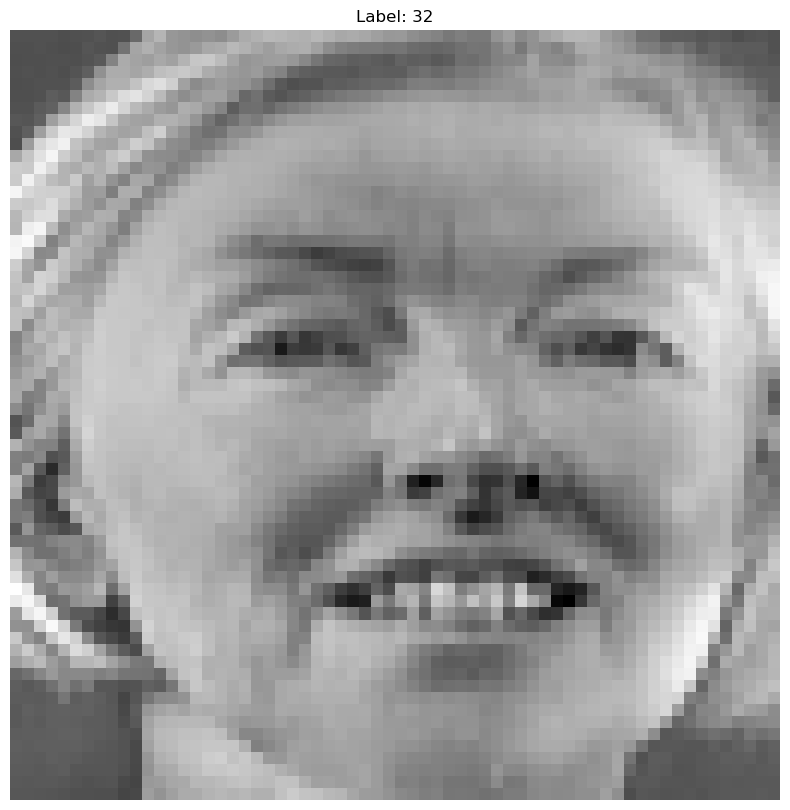

In [43]:
# Function to predict the label for an external image
def predict_external_image(image_path, clf, pca, scaler):
    # Open the image
    with Image.open(image_path) as img:
        # Convert the image to grayscale
        img = img.convert('L')
        # Resize the image to match the training data size (e.g., 64x64)
        img = img.resize((64, 64))
        # Flatten the image into a 1D array
        img_array = np.array(img).flatten()
        # Standardize the image using the same scaler used for training
        img_array = scaler.transform([img_array])
        # Apply PCA transformation
        img_array_pca = pca.transform(img_array)
        # Predict the label using the trained classifier
        predicted_label = clf.predict(img_array_pca)
        return predicted_label[0]

# Path to the external image
image_path = 'test.PNG'
with Image.open(image_path) as img:
    plt.imshow(img, cmap='gray')
    plt.title(f"Predicted Label: {predicted_label}")
    plt.axis('off')
    plt.show()
# Predict the label for the external image
predicted_label = predict_external_image(image_path, clf, pca, scaler)

# Display the predicted label
print(f"Predicted Label for {image_path}: {predicted_label}")
print("Actuall :")
def plot_sample_images(images, labels, num_samples=1):
    plt.figure(figsize=(10, 10))
    for i in range(num_samples):
        plt.subplot(1, num_samples, i+1)
        plt.imshow(images[3].reshape(64, 64), cmap='gray')
        plt.title(f"Label: {labels[3]}")
        plt.axis('off')
    plt.show()

plot_sample_images(X_train, y_train)

### Step 9: Visualize the Results
We include several visualizations to better understand the data and the model's performance:
1. **Sample Images**: Display a few sample images from the dataset.
2. **Explained Variance Ratio**: Plot the cumulative explained variance for PCA.
3. **Confusion Matrix**: Visualize the true vs. predicted labels.
4. **Feature Importance**: Plot the importance of features in the Random Forest model.
5. **ROC Curve**: Plot the Receiver Operating Characteristic (ROC) curve.
6. **Histogram of Predicted Labels**: Show the distribution of predicted labels.

These visualizations provide insights into the dataset and the model's performance.

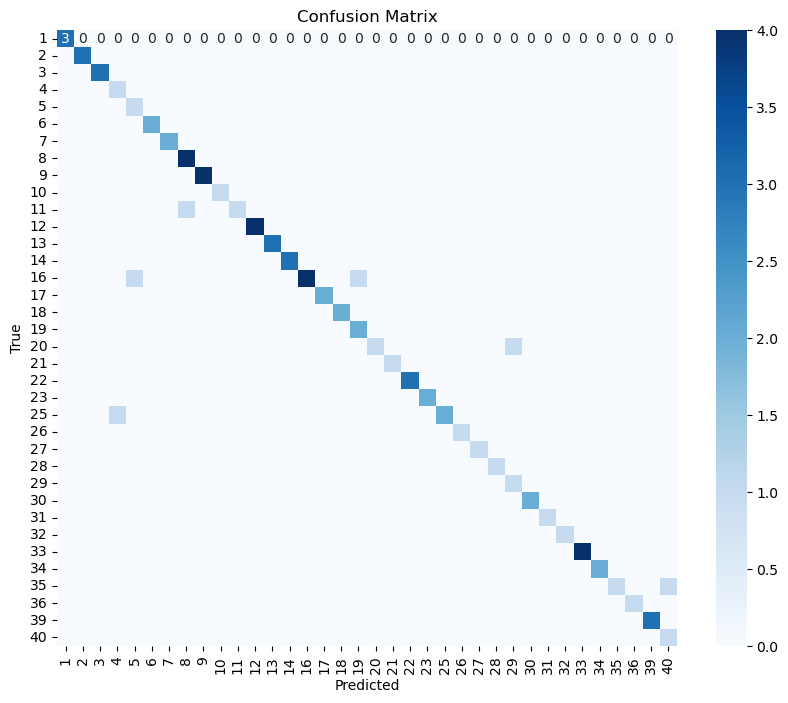

In [24]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y_test), yticklabels=np.unique(y_test))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

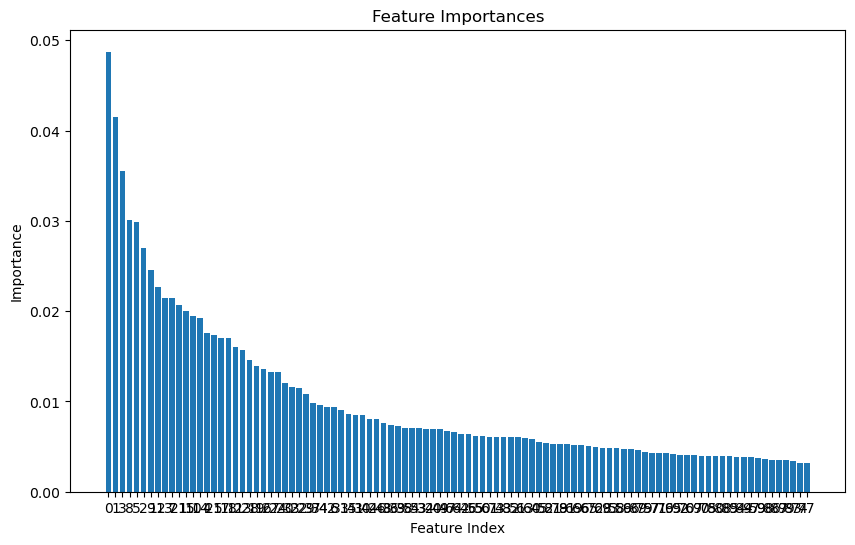

In [25]:
importances = clf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
plt.title("Feature Importances")
plt.bar(range(X_train_pca.shape[1]), importances[indices], align="center")
plt.xticks(range(X_train_pca.shape[1]), indices)
plt.xlabel("Feature Index")
plt.ylabel("Importance")
plt.show()

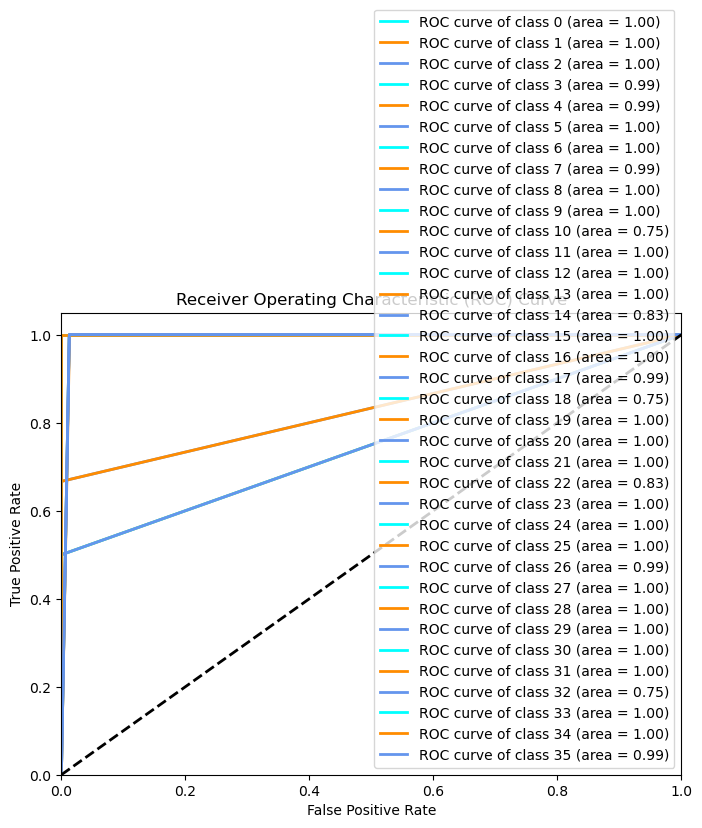

In [26]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from itertools import cycle

# Binarize the output
y_test_bin = label_binarize(y_test, classes=np.unique(y_test))
y_pred_bin = label_binarize(y_pred, classes=np.unique(y_test))

n_classes = y_test_bin.shape[1]

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_bin[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure(figsize=(8, 6))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue'])
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'
             ''.format(i, roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

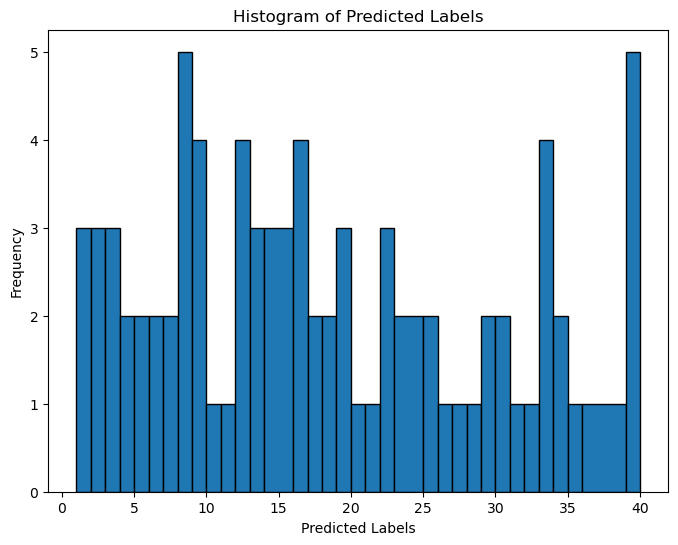

In [27]:
plt.figure(figsize=(8, 6))
plt.hist(y_pred, bins=np.unique(y_test), edgecolor='black')
plt.xlabel('Predicted Labels')
plt.ylabel('Frequency')
plt.title('Histogram of Predicted Labels')
plt.show()

### Step 10: Conclusion
In this project, we:
- Loaded and preprocessed the ORL face dataset.
- Applied PCA for dimensionality reduction.
- Trained a Random Forest classifier and evaluated its performance.
- Tested the model on external images to verify its generalization capability.

The model achieved good accuracy, but there is room for improvement. Potential improvements include:
- Trying other classification algorithms (e.g., SVM, Neural Networks).
- Fine-tuning hyperparameters for better performance.
- Using more advanced feature extraction techniques (e.g., deep learning).

Overall, the project demonstrates the effectiveness of machine learning for face recognition tasks.